# Practical 8: Naïve Bayes Classifier – SMS Spam Detection

**Aim:** To implement Naïve Bayes on the SMS Spam Collection dataset to classify messages as spam or ham.

**Dataset:** [SMS Spam Collection on Kaggle](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

Download and extract `spam.csv`. Keep it in the same folder as this notebook.

In [31]:
# DS libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
# Load dataset
df = pd.read_csv("spam.csv", encoding="latin-1")
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [33]:
# Select required columns
df = df[["v1", "v2"]]
df.columns = ["label", "message"]
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [34]:
# Input and output
X = df["message"]
y = df["label"]

y.value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [35]:
# Convert text into numerical values
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X = cv.fit_transform(X)

In [36]:
# Split the Dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [37]:
# Naive Bayes algorithm
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()

In [38]:
# Training
nb.fit(X_train, y_train)

MultinomialNB()

In [39]:
# Check training data accuracy
nb.score(X_train, y_train) * 100

99.43908458604443

In [40]:
# Testing
y_pred = nb.predict(X_test)
y_pred[:10]

array(['spam', 'ham', 'spam', 'ham', 'spam', 'ham', 'ham', 'ham', 'ham',
       'ham'], dtype='<U4')

In [41]:
# Actual test output
y_test[:10]

3245     ham
944      ham
1044    spam
2484     ham
812     spam
2973     ham
2991     ham
2942     ham
230      ham
1181     ham
Name: label, dtype: object

In [42]:
# Performance evaluation
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
print("Accuracy:", accuracy_score(y_test, y_pred) * 100)
print(classification_report(y_test, y_pred))

Accuracy: 97.847533632287
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       965
        spam       0.91      0.93      0.92       150

    accuracy                           0.98      1115
   macro avg       0.95      0.96      0.95      1115
weighted avg       0.98      0.98      0.98      1115



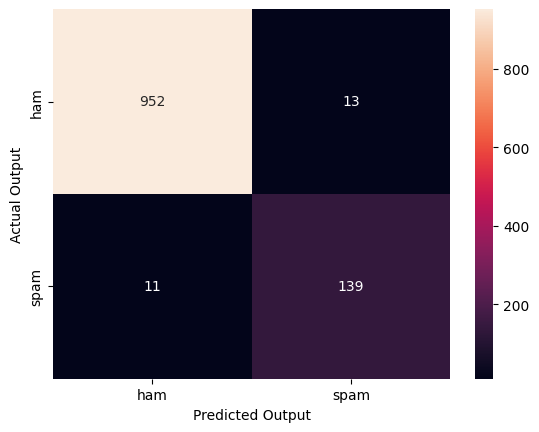

In [43]:
# Confusion matrix
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)
plt.xlabel("Predicted Output")
plt.ylabel("Actual Output")
plt.show()

In [44]:
# Test a new message
msg = ["Congratulations! You have won a free prize. Call now!"]
msg = cv.transform(msg)
print("Prediction:", nb.predict(msg)[0])

Prediction: spam


In [45]:
# Test a ham message
ham_msg = ["Hey, are we still meeting for lunch today?"]
ham_msg = cv.transform(ham_msg)
print("Prediction:", nb.predict(ham_msg)[0])

Prediction: ham


## Conclusion

The Multinomial Naïve Bayes classifier was implemented on the SMS Spam Collection dataset. Messages were classified as ham or spam, and performance was evaluated using accuracy, confusion matrix, and classification report.